# Statistical Report: Student Exam Performance
**Course:** BIT 4131 Statistical Computing and Reporting
**Author:** Yvonne Odhiambo

## 1. Introduction
This report analyses exam scores of 1,000 students in mathematics, reading
and writing. It asks three questions:
1. How are the scores distributed?
2. Do male and female students differ in their scores?
3. Is completing the test-preparation course associated with higher scores?

Every number, table and chart below is produced by the code in this notebook,
so the whole report can be re-run to give identical results.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

df = pd.read_csv(Path.cwd().parent / "data" / "Cleaned_Students_Performance.csv")
df.columns = [c.replace(" ", "_").replace("/", "_") for c in df.columns]

# 0/1 codes inferred from the original Kaggle data
if pd.api.types.is_numeric_dtype(df["gender"]):
    df["gender"] = df["gender"].map({0: "female", 1: "male"})
if pd.api.types.is_numeric_dtype(df["test_preparation_course"]):
    df["test_preparation_course"] = df["test_preparation_course"].map(
        {1: "completed", 0: "none"})

scores = ["math_score", "reading_score", "writing_score"]
print("Rows, columns:", df.shape)
print("Missing values:", int(df[scores].isna().sum().sum()))

Rows, columns: (1000, 10)
Missing values: 0


## 2. Data
The data are the *Students Performance in Exams* dataset (Kaggle), in a cleaned
version. Each row is one student. The scores range from 0 to 100.
Gender and test-preparation status are stored as 0/1 codes and are converted
to labels in the code above.

## 3. Descriptive statistics

In [2]:
summary = df[scores].describe().T
summary["median"] = df[scores].median()
summary["skewness"] = df[scores].skew()
summary = summary[["count", "mean", "median", "std", "min", "max", "skewness"]].round(2)
summary.to_csv("output/summary_table.csv")
summary

,count,mean,median,std,min,max,skewness
math_score,1000.0,66.09,66.0,15.16,0.0,100.0,-0.28
reading_score,1000.0,69.17,70.0,14.60,17.0,100.0,-0.26
writing_score,1000.0,68.05,69.0,15.20,10.0,100.0,-0.29


## 4. Graphs

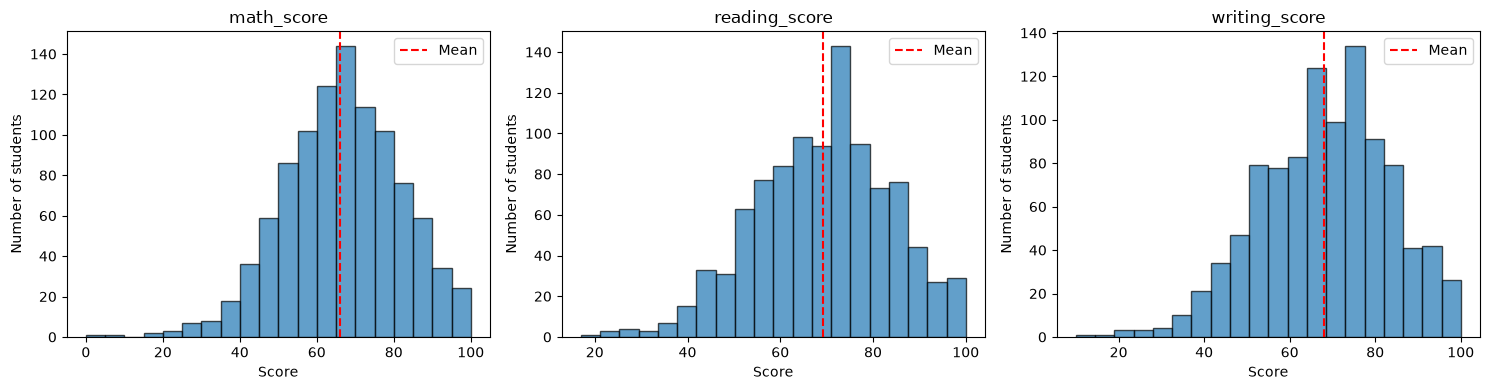

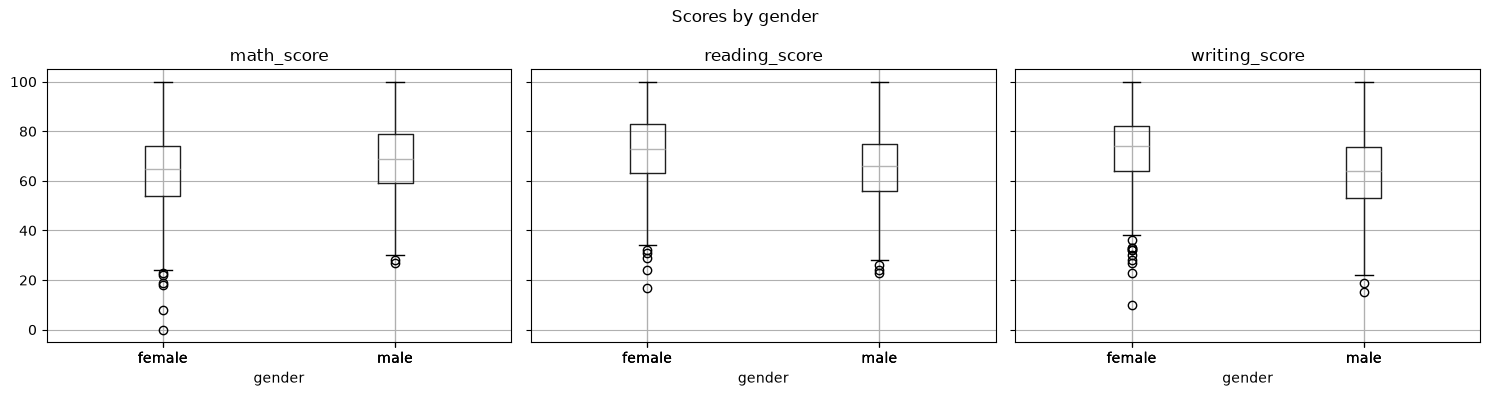

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, scores):
    ax.hist(df[col], bins=20, edgecolor="black", alpha=0.7)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label="Mean")
    ax.set_title(col)
    ax.set_xlabel("Score")
    ax.set_ylabel("Number of students")
    ax.legend()
plt.tight_layout()
plt.savefig("output/histograms.png", dpi=150)
plt.show()

df.boxplot(column=scores, by="gender", layout=(1, 3), figsize=(15, 4))
plt.suptitle("Scores by gender")
plt.tight_layout()
plt.savefig("output/boxplots_by_gender.png", dpi=150)
plt.show()

## 5. Statistical analysis

In [4]:
# Question 2: gender differences (Welch t-test and Cohen's d)
rows = []
for col in scores:
    f = df.loc[df["gender"] == "female", col]
    m = df.loc[df["gender"] == "male", col]
    t, p = stats.ttest_ind(m, f, equal_var=False)
    pooled = np.sqrt((f.var() + m.var()) / 2)
    rows.append({"score": col, "female_mean": f.mean(), "male_mean": m.mean(),
                 "difference": m.mean() - f.mean(), "t": t, "p_value": p,
                 "cohens_d": (m.mean() - f.mean()) / pooled})
gender_tbl = pd.DataFrame(rows).round(4)
gender_tbl.to_csv("output/gender_tests.csv", index=False)
gender_tbl

,score,female_mean,male_mean,difference,t,p_value,cohens_d
0,math_score,63.6332,68.7282,5.0950,5.3980,0.0,0.3412
1,reading_score,72.6081,65.4730,-7.1351,-7.9684,0.0,-0.5040
2,writing_score,72.4672,63.3112,-9.1560,-9.9977,0.0,-0.6321


In [5]:
# Question 3: test preparation (Welch t-test and Cohen's d)
rows = []
for col in scores:
    c = df.loc[df["test_preparation_course"] == "completed", col]
    n_ = df.loc[df["test_preparation_course"] == "none", col]
    t, p = stats.ttest_ind(c, n_, equal_var=False)
    pooled = np.sqrt((c.var() + n_.var()) / 2)
    rows.append({"score": col, "completed_mean": c.mean(), "none_mean": n_.mean(),
                 "difference": c.mean() - n_.mean(), "t": t, "p_value": p,
                 "cohens_d": (c.mean() - n_.mean()) / pooled})
prep_tbl = pd.DataFrame(rows).round(4)
prep_tbl.to_csv("output/prep_tests.csv", index=False)
prep_tbl

,score,completed_mean,none_mean,difference,t,p_value,cohens_d
0,math_score,69.6955,64.0779,5.6176,5.7870,0.0,0.3790
1,reading_score,73.8939,66.5343,7.3596,8.0041,0.0,0.5235
2,writing_score,74.4190,64.5047,9.9143,10.7525,0.0,0.6977


In [6]:
corr = df[scores].corr().round(3)
corr.to_csv("output/correlations.csv")
corr

,math_score,reading_score,writing_score
math_score,1.000,0.818,0.803
reading_score,0.818,1.000,0.955
writing_score,0.803,0.955,1.000


## 6. Interpretation

In [7]:
g = gender_tbl.set_index("score")
p_ = prep_tbl.set_index("score")

def verdict(p):
    return "statistically significant" if p < 0.05 else "not statistically significant"

lines = []
lines.append(f"- **Distribution.** Mean scores are {summary.loc['math_score','mean']:.1f} "
             f"(math), {summary.loc['reading_score','mean']:.1f} (reading) and "
             f"{summary.loc['writing_score','mean']:.1f} (writing). "
             f"Skewness is slightly negative for all three, so each has a longer tail "
             f"of low scores.")
for col in scores:
    d = g.loc[col, "difference"]
    who = "males" if d > 0 else "females"
    lines.append(f"- **Gender, {col}.** {who.capitalize()} scored {abs(d):.1f} points higher "
                 f"on average (p = {g.loc[col,'p_value']:.4g}, d = {g.loc[col,'cohens_d']:.2f}); "
                 f"the difference is {verdict(g.loc[col,'p_value'])}.")
for col in scores:
    lines.append(f"- **Test preparation, {col}.** Students who completed the course scored "
                 f"{p_.loc[col,'difference']:.1f} points {'higher' if p_.loc[col,'difference']>0 else 'lower'} "
                 f"(p = {p_.loc[col,'p_value']:.4g}, d = {p_.loc[col,'cohens_d']:.2f}); "
                 f"{verdict(p_.loc[col,'p_value'])}.")
lines.append(f"- **Correlation.** The scores are strongly related: math and reading "
             f"r = {corr.loc['math_score','reading_score']:.2f}, reading and writing "
             f"r = {corr.loc['reading_score','writing_score']:.2f}.")
display(Markdown("\n".join(lines)))

- **Distribution.** Mean scores are 66.1 (math), 69.2 (reading) and 68.0 (writing). Skewness is slightly negative for all three, so each has a longer tail of low scores.
- **Gender, math_score.** Males scored 5.1 points higher on average (p = 0, d = 0.34); the difference is statistically significant.
- **Gender, reading_score.** Females scored 7.1 points higher on average (p = 0, d = -0.50); the difference is statistically significant.
- **Gender, writing_score.** Females scored 9.2 points higher on average (p = 0, d = -0.63); the difference is statistically significant.
- **Test preparation, math_score.** Students who completed the course scored 5.6 points higher (p = 0, d = 0.38); statistically significant.
- **Test preparation, reading_score.** Students who completed the course scored 7.4 points higher (p = 0, d = 0.52); statistically significant.
- **Test preparation, writing_score.** Students who completed the course scored 9.9 points higher (p = 0, d = 0.70); statistically significant.
- **Correlation.** The scores are strongly related: math and reading r = 0.82, reading and writing r = 0.95.

## 7. Conclusions
- The three scores are roughly bell-shaped and strongly positively correlated, so
  students who do well in one subject tend to do well in the others.
- The gender comparison and the test-preparation comparison are summarised in
  Section 6 using Welch t-tests (which do not assume equal variances) and
  Cohen's d as the effect size.
- **Limitations.** The data are observational, so the results show association,
  not cause. For example, students who complete the course may differ in other
  ways. The 0/1 coding of the variables was inferred from the original dataset.

## 8. Reproducibility
Run the notebook from top to bottom to regenerate every table and graph.
The software environment used is shown below.

In [8]:
import matplotlib, scipy
print("Python    :", sys.version.split()[0])
print("pandas    :", pd.__version__)
print("numpy     :", np.__version__)
print("scipy     :", scipy.__version__)
print("matplotlib:", matplotlib.__version__)

Python    : 3.11.9
pandas    : 3.0.3
numpy     : 2.4.6
scipy     : 1.17.1
matplotlib: 3.11.0
